Model loaded successfully!
Number of model features: 54
SHAP sample size: 5000
SHAP calculation completed!


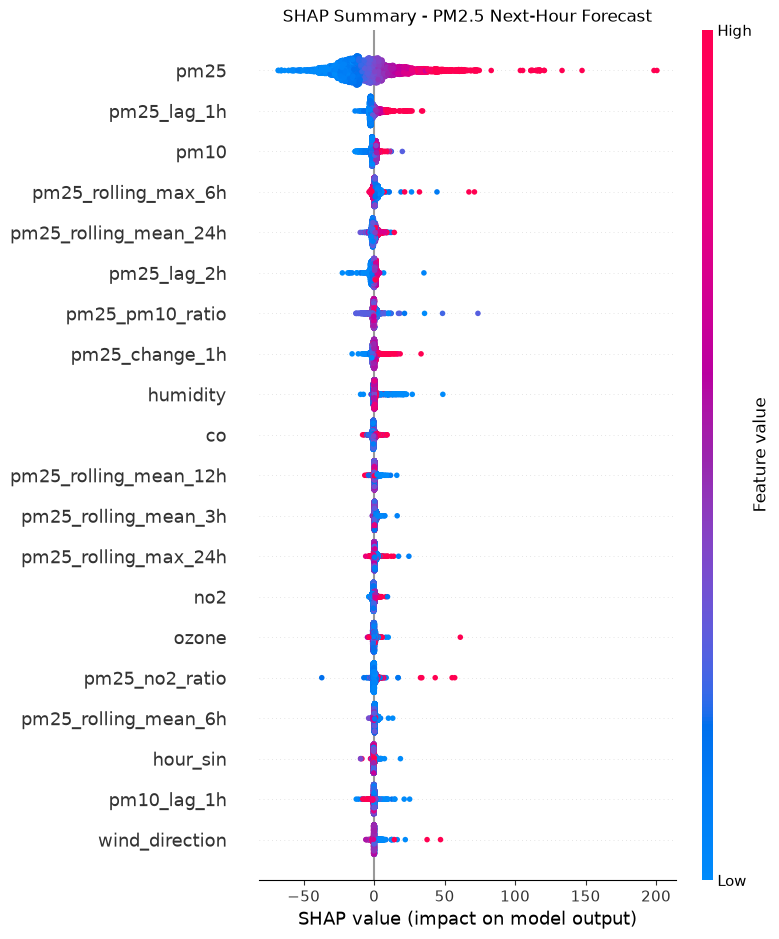

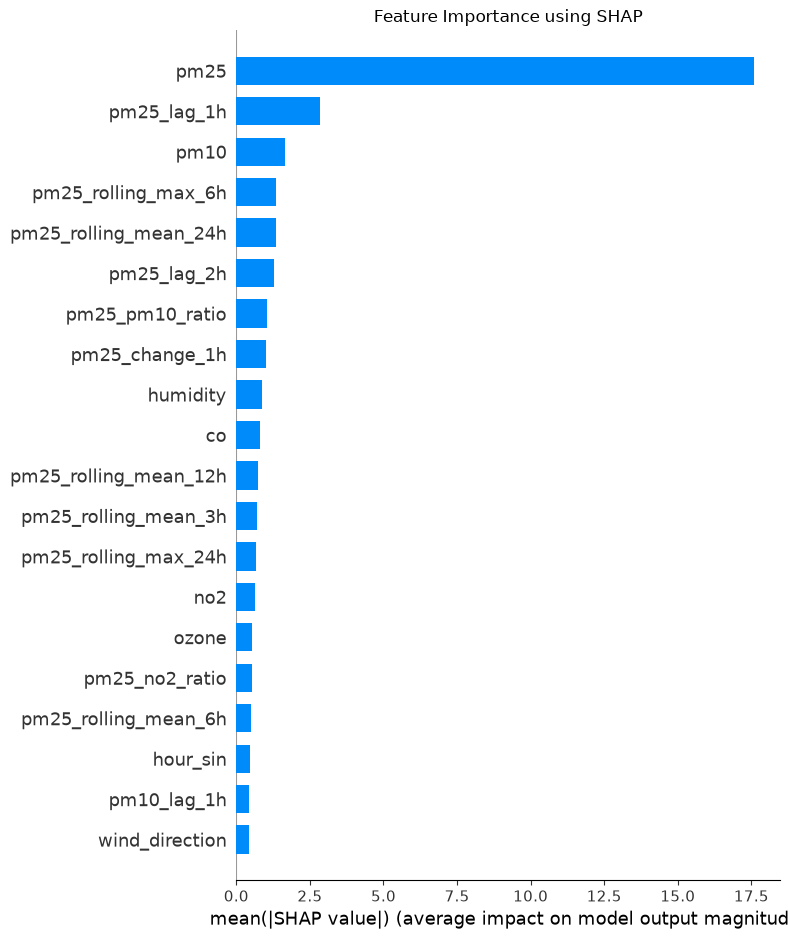


TOP 20 FEATURES
              feature  mean_abs_shap
                 pm25      17.592806
          pm25_lag_1h       2.854495
                 pm10       1.638944
  pm25_rolling_max_6h       1.361131
pm25_rolling_mean_24h       1.334303
          pm25_lag_2h       1.263715
      pm25_pm10_ratio       1.054102
       pm25_change_1h       1.016352
             humidity       0.874806
                   co       0.810499
pm25_rolling_mean_12h       0.734995
 pm25_rolling_mean_3h       0.693953
 pm25_rolling_max_24h       0.679759
                  no2       0.632389
                ozone       0.539246
       pm25_no2_ratio       0.536045
 pm25_rolling_mean_6h       0.502727
             hour_sin       0.459899
          pm10_lag_1h       0.440669
       wind_direction       0.420019

SHAP importance saved to: ../data/processed/shap_feature_importance.csv

Most important feature: pm25


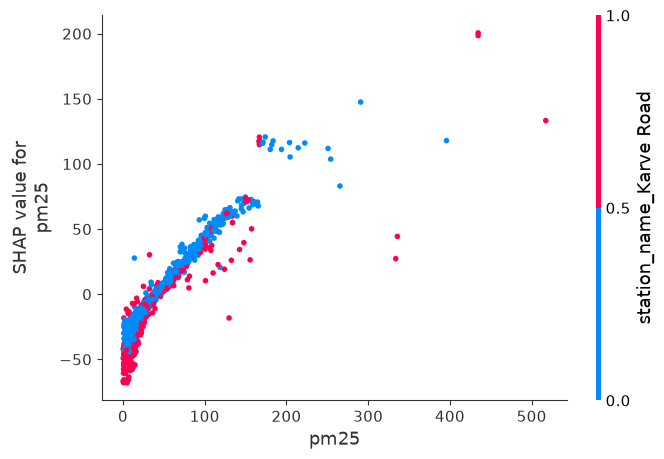


INDIVIDUAL PREDICTION
Predicted next-hour PM2.5: 79.01


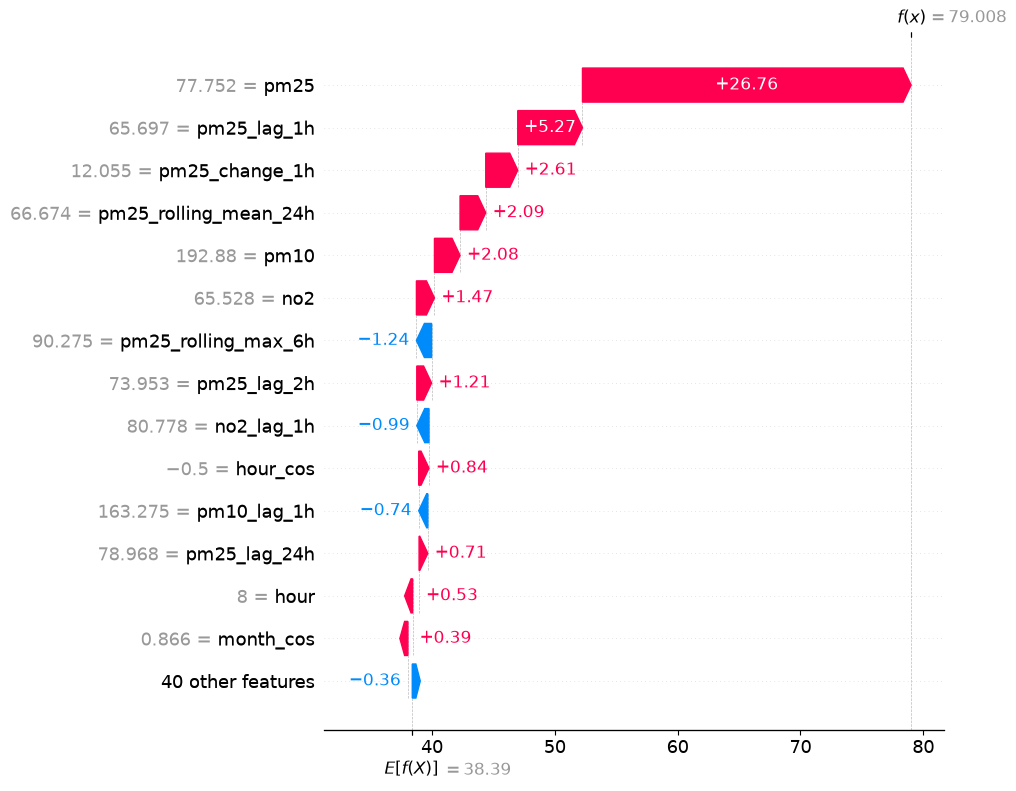


SHAP ANALYSIS COMPLETED


In [2]:
# ============================================================
# SHAP ANALYSIS FOR XGBOOST PM2.5 FORECASTING
# ============================================================

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

# ============================================================
# 1. LOAD TRAINING DATA
# ============================================================

file_path = "../data/processed/pune_cpcb_features.csv"

if not os.path.exists(file_path):
    file_path = "data/processed/pune_cpcb_features.csv"

df = pd.read_csv(file_path)

df["timestamp"] = pd.to_datetime(
    df["timestamp"],
    errors="coerce"
)

df = df.sort_values(
    ["station_name", "timestamp"]
).reset_index(drop=True)


# ============================================================
# 2. CREATE NEXT-HOUR TARGET
# ============================================================

df["target_pm25_next_1h"] = (
    df.groupby("station_name")["pm25"]
      .shift(-1)
)

df = df.dropna(
    subset=["target_pm25_next_1h"]
).copy()


# ============================================================
# 3. ONE-HOT ENCODE STATION
# ============================================================

df_model = pd.get_dummies(
    df,
    columns=["station_name"],
    dtype=int
)


# ============================================================
# 4. CREATE X AND y
# ============================================================

X = df_model.drop(
    columns=["target_pm25_next_1h"]
)

y = df_model["target_pm25_next_1h"]


# Remove timestamp
if "timestamp" in X.columns:
    X = X.drop(columns=["timestamp"])


# Convert to numeric
X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

X = X.replace(
    [np.inf, -np.inf],
    np.nan
)


# ============================================================
# 5. LOAD TRAINED MODEL
# ============================================================

model_path = (
    "../models/forecasting/"
    "xgboost_pm25_forecasting.pkl"
)

if not os.path.exists(model_path):
    model_path = (
        "models/forecasting/"
        "xgboost_pm25_forecasting.pkl"
    )

model = joblib.load(model_path)

print("Model loaded successfully!")


# ============================================================
# 6. MATCH FEATURES WITH MODEL
# ============================================================

feature_path = (
    "../models/forecasting/"
    "feature_names.pkl"
)

if not os.path.exists(feature_path):
    feature_path = (
        "models/forecasting/"
        "feature_names.pkl"
    )

feature_names = joblib.load(feature_path)

print("Number of model features:", len(feature_names))

# Make sure X has exactly the same columns
X = X.reindex(
    columns=feature_names
)


# ============================================================
# 7. HANDLE MISSING VALUES
# ============================================================

X = X.fillna(
    X.median(numeric_only=True)
)


# ============================================================
# 8. SAMPLE DATA FOR SHAP
# ============================================================

# SHAP can be computationally expensive on very large datasets.
# Use a sample for analysis.

sample_size = min(
    5000,
    len(X)
)

X_sample = X.sample(
    n=sample_size,
    random_state=42
)

print(
    "SHAP sample size:",
    len(X_sample)
)


# ============================================================
# 9. CREATE SHAP EXPLAINER
# ============================================================

explainer = shap.TreeExplainer(
    model
)

shap_values = explainer(
    X_sample
)

print("SHAP calculation completed!")


# ============================================================
# 10. SHAP SUMMARY PLOT
# ============================================================

plt.figure(
    figsize=(12, 8)
)

shap.summary_plot(
    shap_values,
    X_sample,
    show=False
)

plt.title(
    "SHAP Summary - PM2.5 Next-Hour Forecast"
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. SHAP BAR PLOT
# ============================================================

plt.figure(
    figsize=(10, 7)
)

shap.summary_plot(
    shap_values,
    X_sample,
    plot_type="bar",
    show=False
)

plt.title(
    "Feature Importance using SHAP"
)

plt.tight_layout()

plt.show()


# ============================================================
# 12. GET TOP FEATURES
# ============================================================

mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": X_sample.columns,
    "mean_abs_shap": mean_abs_shap
})

shap_importance = shap_importance.sort_values(
    "mean_abs_shap",
    ascending=False
).reset_index(drop=True)


print("\n========================================")
print("TOP 20 FEATURES")
print("========================================")

print(
    shap_importance.head(20).to_string(
        index=False
    )
)


# ============================================================
# 13. SAVE SHAP IMPORTANCE
# ============================================================

output_path = (
    "../data/processed/"
    "shap_feature_importance.csv"
)

shap_importance.to_csv(
    output_path,
    index=False
)

print(
    "\nSHAP importance saved to:",
    output_path
)


# ============================================================
# 14. DEPENDENCE PLOT
# ============================================================

# Automatically select most important feature

top_feature = (
    shap_importance.iloc[0]["feature"]
)

print(
    "\nMost important feature:",
    top_feature
)

shap.dependence_plot(
    top_feature,
    shap_values.values,
    X_sample,
    show=True
)


# ============================================================
# 15. LOCAL EXPLANATION
# ============================================================

# Explain one individual prediction

row_number = 0

single_row = X_sample.iloc[
    [row_number]
]

single_shap = explainer(
    single_row
)

print("\n========================================")
print("INDIVIDUAL PREDICTION")
print("========================================")

prediction = model.predict(
    single_row
)[0]

print(
    "Predicted next-hour PM2.5:",
    round(prediction, 2)
)


# ============================================================
# 16. WATERFALL PLOT
# ============================================================

shap.plots.waterfall(
    single_shap[0],
    max_display=15
)


print("\n========================================")
print("SHAP ANALYSIS COMPLETED")
print("========================================")